# 06 · Milestone 2 parameter experiments

**IE 7615 · From Words to Worlds**

Compare guidance scale, sampling steps, and scheduler choice one variable at a time with Stable Diffusion 1.5. This notebook uses the explicit CLIP conditioning verified in Notebook 05. It saves five COCO baselines, three comparison grids, a baseline gallery, and tables for the Milestone 2 report.

Open in Colab, choose **Runtime → Change runtime type → GPU**, and run sections 01–05 to check the setup and save a smoke image. Then run sections 06–07 to generate the full experiment and report. Authorize the Google Drive mount when prompted. The first run needs network access for dependencies and checkpoint weights. The only COCO input is the committed caption manifest.

## 01 · Set up the CUDA runtime

Use the same inference package versions as Notebook 05. Pip is constrained to the runtime's installed PyTorch, TorchVision, and TorchAudio versions, and a small matrix multiply checks FP16 support before downloading weights. If the setup cell asks for a session restart, restart and run from this section again.

In [1]:
import importlib.metadata as metadata
import json
import os
import platform
import shutil
import subprocess
import sys
from pathlib import Path
from tempfile import TemporaryDirectory

import torch
from packaging.version import Version

if sys.version_info < (3, 11):
    raise RuntimeError("Select a Colab runtime with Python 3.11 or newer.")
if not torch.cuda.is_available() or torch.version.cuda is None:
    raise RuntimeError("Select a GPU under Runtime → Change runtime type and rerun this cell.")
if Version(torch.__version__).release < (2, 6):
    raise RuntimeError("Select a Colab GPU runtime with PyTorch 2.6 or newer.")

device = torch.device("cuda", torch.cuda.current_device())
dtype = torch.float16
try:
    probe = torch.ones((8, 8), device=device, dtype=dtype)
    if (probe @ probe)[0, 0].item() != 8.0:
        raise RuntimeError("The FP16 CUDA probe returned an unexpected result.")
    del probe
except RuntimeError as error:
    raise RuntimeError("Choose an NVIDIA GPU runtime with working FP16 support.") from error

inference_pins = {
    "diffusers": "0.42.1",
    "transformers": "5.22.1",
    "accelerate": "1.15.0",
    "safetensors": "0.8.0",
}
runtime_packages = {
    dist.metadata["Name"].lower(): dist.version
    for dist in metadata.distributions()
    if dist.metadata["Name"]
}
torch_packages = {
    name: runtime_packages[name]
    for name in ("torch", "torchvision", "torchaudio")
    if name in runtime_packages
}
if any(runtime_packages.get(name) != version for name, version in inference_pins.items()):
    was_imported = any(
        name in sys.modules
        for name in (*inference_pins, "huggingface_hub", "tokenizers")
    )
    with TemporaryDirectory() as temp_dir:
        constraints = Path(temp_dir) / "colab-torch.txt"
        constraints.write_text(
            "".join(f"{name}=={version}\n" for name, version in torch_packages.items()),
            encoding="utf-8",
        )
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "--constraint", str(constraints)]
            + [f"{name}=={version}" for name, version in inference_pins.items()],
            check=True,
        )
    if was_imported:
        raise RuntimeError("Inference libraries were already imported. Restart the Colab session and run again.")

for name, version in {**torch_packages, **inference_pins}.items():
    if metadata.version(name) != version:
        raise RuntimeError(f"{name} version differs from the expected {version}.")

import numpy as np
from diffusers import StableDiffusionPipeline
from PIL import Image

gpu = torch.cuda.get_device_properties(device)
driver_info = None
if nvidia_smi := shutil.which("nvidia-smi"):
    driver_query = subprocess.run(
        [nvidia_smi, "--query-gpu=index,name,driver_version", "--format=csv,noheader"],
        capture_output=True,
        text=True,
        check=False,
    )
    driver_info = driver_query.stdout.strip() or None
runtime_info = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "device": str(device),
    "gpu": gpu.name,
    "compute_capability": [gpu.major, gpu.minor],
    "gpu_total_memory_bytes": gpu.total_memory,
    "nvidia_smi": driver_info,
    "torch_cuda": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version(),
    "packages": {
        name: metadata.version(name)
        for name in (*torch_packages, *inference_pins, "huggingface-hub", "tokenizers", "numpy", "pillow", "matplotlib")
    },
}
print(json.dumps(runtime_info, indent=2))

{
  "python": "3.13.16",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "device": "cuda:0",
  "gpu": "Tesla T4",
  "compute_capability": [
    7,
    5
  ],
  "gpu_total_memory_bytes": 15637086208,
  "nvidia_smi": "0, Tesla T4, 580.82.07",
  "torch_cuda": "13.0",
  "cudnn": 92800,
  "packages": {
    "torch": "2.14.1+cu130",
    "torchvision": "0.29.1+cu130",
    "torchaudio": "2.11.0+cu130",
    "diffusers": "0.42.1",
    "transformers": "5.22.1",
    "accelerate": "1.15.0",
    "safetensors": "0.8.0",
    "huggingface-hub": "1.33.0",
    "tokenizers": "0.23.3",
    "numpy": "2.4.6",
    "pillow": "11.3.0",
    "matplotlib": "3.10.0"
  }
}


## 02 · Load the COCO captions

Use the five lowest image IDs in `manifests/prompts.json`, the same selection as Notebook 05. The first three of those five enter all three sweeps. Image generation uses seeds `7615–7619` in sorted ID order. The manifest's caption-selection seed is recorded separately.

If you already have a checkout in Colab, set `REPO_DIR` to it. Otherwise this cell tries the repository's Milestone 1 branch. If GitHub is unavailable, upload the repository's `manifests/prompts.json` using **Files → Upload** and rerun this cell. It discovers `/content/prompts.json` automatically. Set `MANIFEST_UPLOAD` to use a different location. An uploaded manifest takes precedence.

In [2]:
import hashlib

REPO_DIR = Path("/content/ie7615-generative-project")
REPO_URL = "https://github.com/connor-rivera/ie7615-generative-project.git"
REPO_REF = "milestone1-complete"
MANIFEST_UPLOAD = Path("/content/prompts.json")
MANIFEST_RELATIVE_PATH = Path("manifests/prompts.json")

repo_root = next(
    (path.resolve() for path in (REPO_DIR, Path.cwd(), *Path.cwd().parents)
     if (path / MANIFEST_RELATIVE_PATH).is_file()),
    None,
)
if repo_root is None and not REPO_DIR.exists() and not MANIFEST_UPLOAD.is_file():
    clone = subprocess.run(
        ["git", "clone", "--depth", "1", "--branch", REPO_REF, REPO_URL, str(REPO_DIR)],
        env={**os.environ, "GIT_TERMINAL_PROMPT": "0"},
        capture_output=True,
        text=True,
        check=False,
    )
    if clone.returncode == 0 and (REPO_DIR / MANIFEST_RELATIVE_PATH).is_file():
        repo_root = REPO_DIR.resolve()

if MANIFEST_UPLOAD.is_file():
    manifest_path = MANIFEST_UPLOAD
    manifest_source = "uploaded"
elif repo_root is not None:
    manifest_path = repo_root / MANIFEST_RELATIVE_PATH
    manifest_source = "repository"
else:
    raise FileNotFoundError(
        "Upload the repository's manifests/prompts.json using Colab Files → Upload, "
        "set MANIFEST_UPLOAD to its path if needed, and rerun section 02."
    )

manifest_bytes = manifest_path.read_bytes()
manifest = json.loads(manifest_bytes)
entries = manifest["prompts"]
if any(type(item["image_id"]) is not int or item["image_id"] <= 0
       or not isinstance(item["prompt"], str) or not item["prompt"].strip() for item in entries):
    raise ValueError("The prompt manifest must contain positive integer image IDs and nonempty captions.")

repo_commit = None
if repo_root is not None:
    sys.path.insert(0, str(repo_root))
    from src.generate_samples import (
        DEFAULT_GUIDANCE_SCALE, DEFAULT_SEED, DEFAULT_STEPS, IMAGE_SIZE, MODEL_ID, NEGATIVE_PROMPT,
    )
    from src.prompts import load_prompts

    prompt_map = load_prompts(manifest_path)
    git_revision = subprocess.run(
        ["git", "-C", str(repo_root), "rev-parse", "HEAD"],
        capture_output=True, text=True, check=False,
    )
    if git_revision.returncode == 0:
        repo_commit = git_revision.stdout.strip()
else:
    # Milestone 1 constants for the standalone manifest-upload path.
    MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
    DEFAULT_SEED, DEFAULT_STEPS, DEFAULT_GUIDANCE_SCALE, IMAGE_SIZE = 7615, 30, 7.5, 512
    NEGATIVE_PROMPT = "blurry, distorted, low quality, duplicate, text, watermark"
    prompt_map = {item["image_id"]: item["prompt"] for item in entries}

if len(prompt_map) < 5 or len(prompt_map) != len(entries) or len(prompt_map) != manifest["n_prompts"]:
    raise ValueError("Expected at least five prompts, unique image IDs, and a consistent manifest count.")

selected_ids = sorted(prompt_map)[:5]
sweep_ids = selected_ids[:3]
samples = {
    image_id: {"image_id": image_id, "prompt": prompt_map[image_id], "seed": DEFAULT_SEED + index}
    for index, image_id in enumerate(selected_ids)
}
manifest_info = {
    "source": manifest_source,
    "path": str(manifest_path),
    "sha256": hashlib.sha256(manifest_bytes).hexdigest(),
    "caption_selection_seed": manifest["seed"],
    "n_prompts": len(prompt_map),
    "selection_rule": "five lowest image IDs; three lowest IDs for sweeps",
    "checkout_commit": repo_commit,
}
print(f"Manifest: {manifest_path} ({len(prompt_map):,} captions)")
for sample in samples.values():
    label = "baseline and sweeps" if sample["image_id"] in sweep_ids else "baseline"
    print(f"COCO {sample['image_id']:012d} · seed {sample['seed']} · {label} · {sample['prompt']}")

Manifest: /content/ie7615-generative-project/manifests/prompts.json (4,785 captions)
COCO 000000000139 · seed 7615 · baseline and sweeps · A room with chairs, a table, and a woman in it.
COCO 000000000285 · seed 7616 · baseline and sweeps · A large bear that is sitting on grass.
COCO 000000000632 · seed 7617 · baseline and sweeps · Bedroom scene with a bookcase, blue comforter and window.
COCO 000000000724 · seed 7618 · baseline · A stop sign is mounted upside-down on it's post.
COCO 000000000776 · seed 7619 · baseline · Three stuffed bears hugging and sitting on a blue pillow


## 03 · Plan the one-variable-at-a-time runs and mount Drive

All images are 512×512. The reference is PNDM with 30 requested steps and CFG 7.5. The five baselines include the three sweep references, so the figures reuse those files. Each of the three sweep prompts adds seven unique settings (three guidance values, two step counts, and two schedulers). The preflight image uses four requested PNDM steps and is tracked separately.

| Sweep | Varied settings | Held fixed |
|---|---|---|
| Classifier-free guidance (CFG) | 1.0, 4.0, 7.5, 10.0 | PNDM, 30 steps |
| Inference steps | 15, 30, 50 | PNDM, CFG 7.5 |
| Scheduler | PNDM, DDIM, Euler | 30 steps, CFG 7.5 |

The same negative text from Notebook 05 is applied whenever CFG is active. At CFG 1.0, Diffusers uses the positive condition by itself. Each run gets its own timestamped Drive folder.

In [3]:
from datetime import datetime, timezone
from typing import NamedTuple

from google.colab import drive


class Settings(NamedTuple):
    scheduler: str
    steps: int
    guidance: float


baseline = Settings("PNDM", DEFAULT_STEPS, DEFAULT_GUIDANCE_SCALE)
sweep_settings = {
    "guidance": [baseline._replace(guidance=value) for value in (1.0, 4.0, 7.5, 10.0)],
    "steps": [baseline._replace(steps=value) for value in (15, 30, 50)],
    "scheduler": [baseline._replace(scheduler=value) for value in ("PNDM", "DDIM", "Euler")],
}
variants = list(dict.fromkeys(
    setting for group in sweep_settings.values() for setting in group if setting != baseline
))
plan = (
    [(image_id, baseline) for image_id in selected_ids]
    + [(image_id, setting) for image_id in sweep_ids for setting in variants]
)
smoke_key = (sweep_ids[0], baseline._replace(steps=4))
assert (IMAGE_SIZE, baseline.steps, baseline.guidance) == (512, 30, 7.5)
assert len(plan) == len(set(plan)) == 26 and smoke_key not in plan
assert all(
    sum(value != reference for value, reference in zip(setting, baseline)) == 1
    for setting in variants
)
print(f"Baseline {baseline} · {len(selected_ids)} captions · {IMAGE_SIZE}×{IMAGE_SIZE}")
for group, settings in sweep_settings.items():
    print(f"{group}: {settings}")
print(f"Planned: {len(plan)} unique experiment images plus 1 smoke image")
print(f"Negative text with CFG > 1: {NEGATIVE_PROMPT}")

drive.mount("/content/drive")
drive_root = Path("/content/drive/MyDrive")
if not drive_root.is_dir():
    raise RuntimeError("Authorize the Google Drive mount and rerun this section.")
started_at = datetime.now(timezone.utc)
run_id = started_at.strftime("%Y%m%dT%H%M%S.%fZ")
run_dir = drive_root / "IE7615" / "milestone2" / "parameter_experiments" / run_id
run_dir.mkdir(parents=True, exist_ok=False)
(run_dir / "images").mkdir()
print(f"Run folder: {run_dir}")

Baseline Settings(scheduler='PNDM', steps=30, guidance=7.5) · 5 captions · 512×512
guidance: [Settings(scheduler='PNDM', steps=30, guidance=1.0), Settings(scheduler='PNDM', steps=30, guidance=4.0), Settings(scheduler='PNDM', steps=30, guidance=7.5), Settings(scheduler='PNDM', steps=30, guidance=10.0)]
steps: [Settings(scheduler='PNDM', steps=15, guidance=7.5), Settings(scheduler='PNDM', steps=30, guidance=7.5), Settings(scheduler='PNDM', steps=50, guidance=7.5)]
scheduler: [Settings(scheduler='PNDM', steps=30, guidance=7.5), Settings(scheduler='DDIM', steps=30, guidance=7.5), Settings(scheduler='Euler', steps=30, guidance=7.5)]
Planned: 26 unique experiment images plus 1 smoke image
Negative text with CFG > 1: blurry, distorted, low quality, duplicate, text, watermark
Mounted at /content/drive
Run folder: /content/drive/MyDrive/IE7615/milestone2/parameter_experiments/20261120T162837.037381Z


## 04 · Load SD 1.5 and prepare conditioning

Load the pinned Notebook 05 checkpoint once in FP16, keeping the checkpoint's safety checker. Use batch size one and PyTorch's default attention path to fit a T4. Tokenize each caption with the pipeline's CLIP tokenizer and take the encoder's full sequence of hidden states. Encode the shared negative prompt once.

For every image, build a fresh scheduler from the original PNDM configuration. Preserve the checkpoint's beta schedule, epsilon prediction, step offset, and leading timestep spacing where supported. DDIM uses zero eta. Euler here is `EulerDiscreteScheduler`. We reuse each prompt's unscaled Gaussian noise across conditions. Diffusers applies each scheduler's initial noise sigma internally, so the saved noise hash identifies the shared draw while the logged sigma describes each scheduler's effective input scale.

In [4]:
from diffusers import DDIMScheduler, EulerDiscreteScheduler, PNDMScheduler

MODEL_REVISION = "451f4fe16113bff5a5d2269ed5ad43b0592e9a14"
model_load = {"revision": MODEL_REVISION, "dtype": dtype, "use_safetensors": True}
pipe = StableDiffusionPipeline.from_pretrained(MODEL_ID, **model_load).to(device)
pipe.set_progress_bar_config(leave=False)
for module in (pipe.text_encoder, pipe.unet, pipe.vae):
    module.eval()
    parameter = next(module.parameters())
    if parameter.device != device or parameter.dtype != dtype:
        raise RuntimeError(f"{type(module).__name__} must be on {device} in FP16.")
if not isinstance(pipe.scheduler, PNDMScheduler):
    raise RuntimeError("The checkpoint scheduler must be PNDM for the baseline.")
if pipe.unet.config.time_cond_proj_dim is not None:
    raise RuntimeError("This experiment requires standard Stable Diffusion classifier-free guidance.")

scheduler_classes = {"PNDM": PNDMScheduler, "DDIM": DDIMScheduler, "Euler": EulerDiscreteScheduler}
checkpoint_scheduler_config = dict(pipe.scheduler.config)


def fresh_scheduler(name):
    return scheduler_classes[name].from_config(
        checkpoint_scheduler_config,
        timestep_spacing=checkpoint_scheduler_config["timestep_spacing"],
    )


scheduler_configs = {name: dict(fresh_scheduler(name).config) for name in scheduler_classes}
for name, config in scheduler_configs.items():
    for field in ("num_train_timesteps", "beta_start", "beta_end", "beta_schedule",
                  "prediction_type", "steps_offset", "timestep_spacing"):
        if config[field] != checkpoint_scheduler_config[field]:
            raise RuntimeError(f"{name} differs from the checkpoint's {field}.")

token_count = pipe.tokenizer.model_max_length
hidden_size = pipe.text_encoder.config.hidden_size
assert (token_count, hidden_size, pipe.unet.config.cross_attention_dim) == (77, 768, 768)
latent_shape = (1, pipe.unet.config.in_channels, IMAGE_SIZE // pipe.vae_scale_factor,
                IMAGE_SIZE // pipe.vae_scale_factor)
assert latent_shape == (1, 4, 64, 64)
components = {name: type(component).__name__ if component is not None else None
              for name, component in pipe.components.items()}
attention_processors = sorted({type(processor).__name__ for processor in pipe.unet.attn_processors.values()})


@torch.inference_mode()
def encode_clip(text):
    tokens = pipe.tokenizer(
        [text], padding="max_length", truncation=True, max_length=token_count, return_tensors="pt"
    )
    attention_mask = (
        tokens.attention_mask.to(device)
        if getattr(pipe.text_encoder.config, "use_attention_mask", False)
        else None
    )
    hidden = pipe.text_encoder(
        input_ids=tokens.input_ids.to(device), attention_mask=attention_mask
    ).last_hidden_state
    assert hidden.shape == (1, token_count, hidden_size) and hidden.dtype == dtype and hidden.device == device
    if not torch.isfinite(hidden).all().item():
        raise RuntimeError("Nonfinite CLIP hidden state.")
    return hidden


positive_embeddings = {image_id: encode_clip(sample["prompt"]) for image_id, sample in samples.items()}
negative_embedding = encode_clip(NEGATIVE_PROMPT)

noise_by_id = {}
for image_id, sample in samples.items():
    generator = torch.Generator(device="cpu").manual_seed(sample["seed"])
    noise_by_id[image_id] = torch.randn(latent_shape, generator=generator, dtype=torch.float32,
                                        device="cpu").to(dtype)
noise_hashes = {image_id: hashlib.sha256(noise.numpy().tobytes()).hexdigest()
                for image_id, noise in noise_by_id.items()}
print(f"{MODEL_ID} @ {MODEL_REVISION} · {dtype}")
print(json.dumps(components, indent=2))
print("Scheduler classes:", {name: cls.__name__ for name, cls in scheduler_classes.items()})
print(f"CLIP context per text: {tuple(negative_embedding.shape)} · initial noise: {latent_shape}")

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

stable-diffusion-v1-5/stable-diffusion-v1-5 @ 451f4fe16113bff5a5d2269ed5ad43b0592e9a14 · torch.float16
{
  "vae": "AutoencoderKL",
  "text_encoder": "CLIPTextModel",
  "tokenizer": "CLIPTokenizer",
  "unet": "UNet2DConditionModel",
  "scheduler": "PNDMScheduler",
  "safety_checker": "StableDiffusionSafetyChecker",
  "feature_extractor": "CLIPImageProcessor",
  "image_encoder": null
}
Scheduler classes: {'PNDM': 'PNDMScheduler', 'DDIM': 'DDIMScheduler', 'Euler': 'EulerDiscreteScheduler'}
CLIP context per text: (1, 77, 768) · initial noise: (1, 4, 64, 64)


## 05 · Run a one-prompt smoke test

Generate and verify the first COCO caption with four requested steps, still at the full image resolution. This checks the pipeline, CUDA, callbacks, and Drive output before the longer sweep. A row in `runs.csv` and `run.json` records the smoke test so it can be identified and excluded from the experiment tables.

Generation time is synchronized CUDA wall-clock time for the pipeline call, including decoding and the safety check. Model loading, CLIP encoding, and Drive writes are outside the timer. Scheduler timesteps are also recorded because requested steps can differ from actual denoising calls.

In [5]:
import csv
from time import perf_counter

fixed_inference = {
    "height": IMAGE_SIZE,
    "width": IMAGE_SIZE,
    "num_images_per_prompt": 1,
    "guidance_rescale": 0.0,
    "eta": 0.0,
    "clip_skip": None,
    "output_type": "pil",
}
package_versions = runtime_info["packages"]
run_metadata = {
    "run_id": run_id,
    "started_at_utc": started_at.isoformat(),
    "status": "running",
    "manifest": manifest_info,
    "model": {
        "id": MODEL_ID, **model_load, "dtype": str(dtype),
        "components": components, "unet_attention_processors": attention_processors,
    },
    "runtime": runtime_info,
    "fixed_inference": fixed_inference,
    "negative_prompt_policy": {"text": NEGATIVE_PROMPT, "apply_if_guidance_above": 1.0},
    "noise": {
        "algorithm": "seeded CPU float32 normal, cast to contiguous CPU FP16 before transfer",
        "shape": list(latent_shape),
        "hash": "SHA-256 of unscaled CPU FP16 tensor bytes in C order",
        "scaling": "StableDiffusionPipeline.prepare_latents applies scheduler.init_noise_sigma once",
    },
    "checkpoint_scheduler_config": checkpoint_scheduler_config,
    "scheduler_configs": scheduler_configs,
    "baseline": baseline._asdict(),
    "sweeps": {name: [setting._asdict() for setting in group] for name, group in sweep_settings.items()},
    "captions": list(samples.values()),
    "sweep_image_ids": sweep_ids,
    "planned_experiment_images": len(plan),
    "runs": [],
}
completed = {}
csv_columns = (
    "run_id", "phase", "image_id", "prompt", "seed", "conditioning", "width", "height",
    "scheduler", "scheduler_class", "requested_steps", "actual_steps", "actual_timesteps",
    "guidance_scale", "cfg_enabled", "negative_prompt_policy_text", "negative_prompt_applied",
    "eta", "num_images_per_prompt", "guidance_rescale", "clip_skip", "output_type",
    "initial_noise_sha256", "initial_noise_sigma", "pipeline_seconds", "safety_checker_flag", "image_path",
    "model_id", "model_revision", "dtype", "use_safetensors", "gpu", "cuda", "python",
    "torch_version", "diffusers_version", "transformers_version", "packages", "scheduler_config",
)


def write_metadata():
    json_path = run_dir / "run.json"
    json_pending = json_path.with_suffix(".json.tmp")
    json_pending.write_text(json.dumps(run_metadata, indent=2, allow_nan=False) + "\n", encoding="utf-8")
    json_pending.replace(json_path)

    csv_path = run_dir / "runs.csv"
    csv_pending = csv_path.with_suffix(".csv.tmp")
    with csv_pending.open("w", encoding="utf-8", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=csv_columns)
        writer.writeheader()
        for row in run_metadata["runs"]:
            writer.writerow({
                **row,
                "actual_timesteps": json.dumps(row["actual_timesteps"]),
                "packages": json.dumps(package_versions, sort_keys=True),
                "scheduler_config": json.dumps(scheduler_configs[row["scheduler"]], sort_keys=True),
            })
    csv_pending.replace(csv_path)


@torch.inference_mode()
def generate(image_id, setting, phase):
    sample = samples[image_id]
    scheduler = fresh_scheduler(setting.scheduler)
    pipe.scheduler = scheduler
    cfg_enabled = setting.guidance > 1.0
    denoising_calls = 0

    def count_step(_pipeline, _index, _timestep, tensors):
        nonlocal denoising_calls
        denoising_calls += 1
        return tensors

    latents = noise_by_id[image_id].to(device, copy=True)
    generator = torch.Generator(device="cpu").manual_seed(sample["seed"])
    torch.cuda.synchronize(device)
    start = perf_counter()
    result = pipe(
        prompt_embeds=positive_embeddings[image_id],
        negative_prompt_embeds=negative_embedding if cfg_enabled else None,
        guidance_scale=setting.guidance,
        num_inference_steps=setting.steps,
        latents=latents,
        generator=generator,
        callback_on_step_end=count_step,
        callback_on_step_end_tensor_inputs=[],
        **fixed_inference,
    )
    torch.cuda.synchronize(device)
    elapsed = perf_counter() - start
    actual_timesteps = scheduler.timesteps.detach().cpu().tolist()
    if denoising_calls <= 0 or len(actual_timesteps) != denoising_calls:
        raise RuntimeError("Actual scheduler timesteps and denoising calls differ.")
    if pipe.do_classifier_free_guidance != cfg_enabled:
        raise RuntimeError("The pipeline's guidance state differs from the planned setting.")

    image = result.images[0]
    if image.size != (IMAGE_SIZE, IMAGE_SIZE) or image.mode != "RGB":
        raise RuntimeError(f"Unexpected image format: {image.mode} {image.size}.")
    filename = (
        f"{phase}_coco_{image_id:012d}_seed_{sample['seed']}_"
        f"{setting.scheduler.lower()}_{setting.steps}steps_cfg{setting.guidance:g}.png"
    )
    image_path = Path("images") / filename
    image.save(run_dir / image_path)
    with Image.open(run_dir / image_path) as saved_image:
        saved_image.verify()
    flags = result.nsfw_content_detected
    row = {
        "run_id": run_id, "phase": phase, **sample,
        "conditioning": "prompt_embeds",
        **fixed_inference,
        "scheduler": setting.scheduler, "scheduler_class": type(scheduler).__name__,
        "requested_steps": setting.steps, "actual_steps": denoising_calls,
        "actual_timesteps": actual_timesteps,
        "guidance_scale": setting.guidance, "cfg_enabled": cfg_enabled,
        "negative_prompt_policy_text": NEGATIVE_PROMPT, "negative_prompt_applied": cfg_enabled,
        "initial_noise_sha256": noise_hashes[image_id], "initial_noise_sigma": float(scheduler.init_noise_sigma),
        "pipeline_seconds": elapsed, "safety_checker_flag": None if flags is None else bool(flags[0]),
        "image_path": image_path.as_posix(),
        "model_id": MODEL_ID, "model_revision": MODEL_REVISION,
        "dtype": str(dtype), "use_safetensors": model_load["use_safetensors"],
        "gpu": runtime_info["gpu"], "cuda": runtime_info["torch_cuda"], "python": runtime_info["python"],
        "torch_version": package_versions["torch"], "diffusers_version": package_versions["diffusers"],
        "transformers_version": package_versions["transformers"],
    }
    run_metadata["runs"].append(row)
    completed[(image_id, setting)] = row
    write_metadata()
    print(f"{phase} · {image_id:012d} · {setting.scheduler} · CFG {setting.guidance:g} · "
          f"{setting.steps} requested / {denoising_calls} actual · {elapsed:.2f} s")
    return row


write_metadata()
smoke = generate(*smoke_key, phase="smoke")
assert smoke["actual_steps"] > 0 and (run_dir / smoke["image_path"]).is_file()
print("Smoke test passed. Continue to section 06.")

  0%|          | 0/4 [00:00<?, ?it/s]

smoke · 000000000139 · PNDM · CFG 7.5 · 4 requested / 5 actual · 2.47 s
Smoke test passed. Continue to section 06.


## 06 · Generate the baselines and the three sweeps

Generate the five references first, followed by the seven alternate configurations per sweep caption. Each condition starts from a copy of the same unscaled latent for its image ID and a freshly seeded generator. The notebook writes each image and updates both metadata files as it goes. With the current session still connected, rerunning this section skips completed settings.

In [6]:
assert smoke_key in completed, "Run the smoke test in section 05 first."
for image_id, setting in plan:
    if (image_id, setting) not in completed:
        phase = "baseline" if setting == baseline else "sweep"
        generate(image_id, setting, phase=phase)

assert set(completed) == {smoke_key, *plan}
assert len(run_metadata["runs"]) == len(completed) == 27
for image_id, setting in plan:
    row = completed[(image_id, setting)]
    assert row["seed"] == samples[image_id]["seed"]
    assert row["initial_noise_sha256"] == completed[(image_id, baseline)]["initial_noise_sha256"]
    assert row["negative_prompt_applied"] == (setting.guidance > 1.0)
    assert (run_dir / row["image_path"]).is_file()
print(f"Saved {len(plan)} experiment images and one smoke image to {run_dir / 'images'}")

  0%|          | 0/30 [00:00<?, ?it/s]

baseline · 000000000139 · PNDM · CFG 7.5 · 30 requested / 31 actual · 4.74 s


  0%|          | 0/30 [00:00<?, ?it/s]

baseline · 000000000285 · PNDM · CFG 7.5 · 30 requested / 31 actual · 4.81 s


  0%|          | 0/30 [00:00<?, ?it/s]

baseline · 000000000632 · PNDM · CFG 7.5 · 30 requested / 31 actual · 4.84 s


... (42 outputs left out)

  0%|          | 0/30 [00:00<?, ?it/s]

sweep · 000000000632 · DDIM · CFG 7.5 · 30 requested / 30 actual · 5.32 s


  0%|          | 0/30 [00:00<?, ?it/s]

sweep · 000000000632 · Euler · CFG 7.5 · 30 requested / 30 actual · 5.29 s
Saved 26 experiment images and one smoke image to /content/drive/MyDrive/IE7615/milestone2/parameter_experiments/20261120T162837.037381Z/images


## 07 · Build the comparison grids and report tables

Rows in each comparison grid use the same COCO image ID, caption, and seed. Columns change the tested setting and mark the shared baseline. The baseline gallery shows all five captions.

The report summarizes the measured step counts, initialization scales, and pipeline times for each setting across the same three captions. Inspect the grids when writing your qualitative observations. The run uses one seed per caption, so timing and image comparisons describe this run on this hardware. FID, Inception Score, and training are outside this experiment.

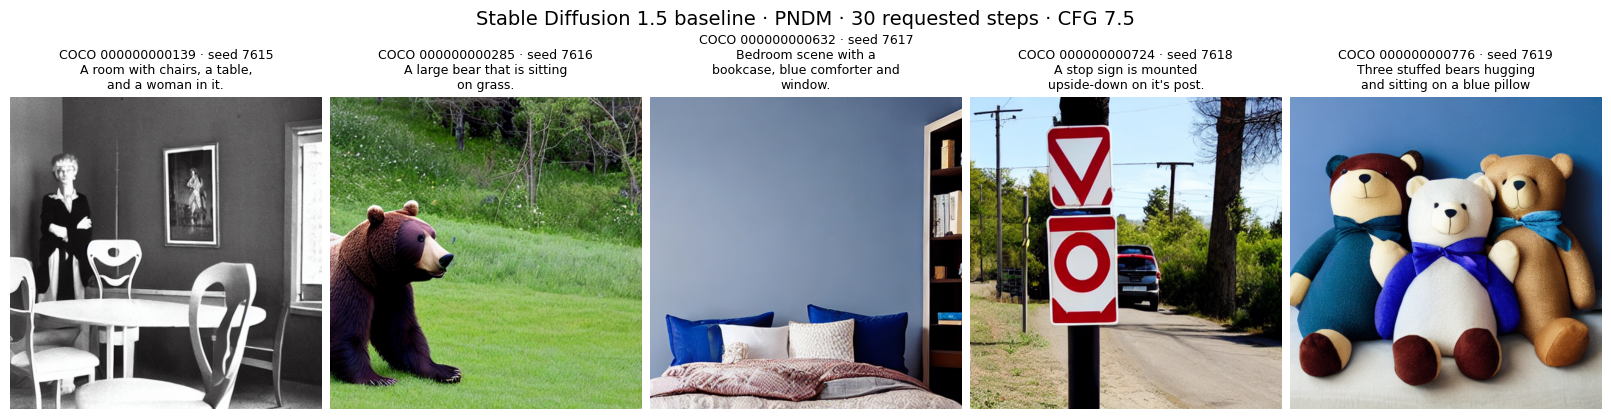

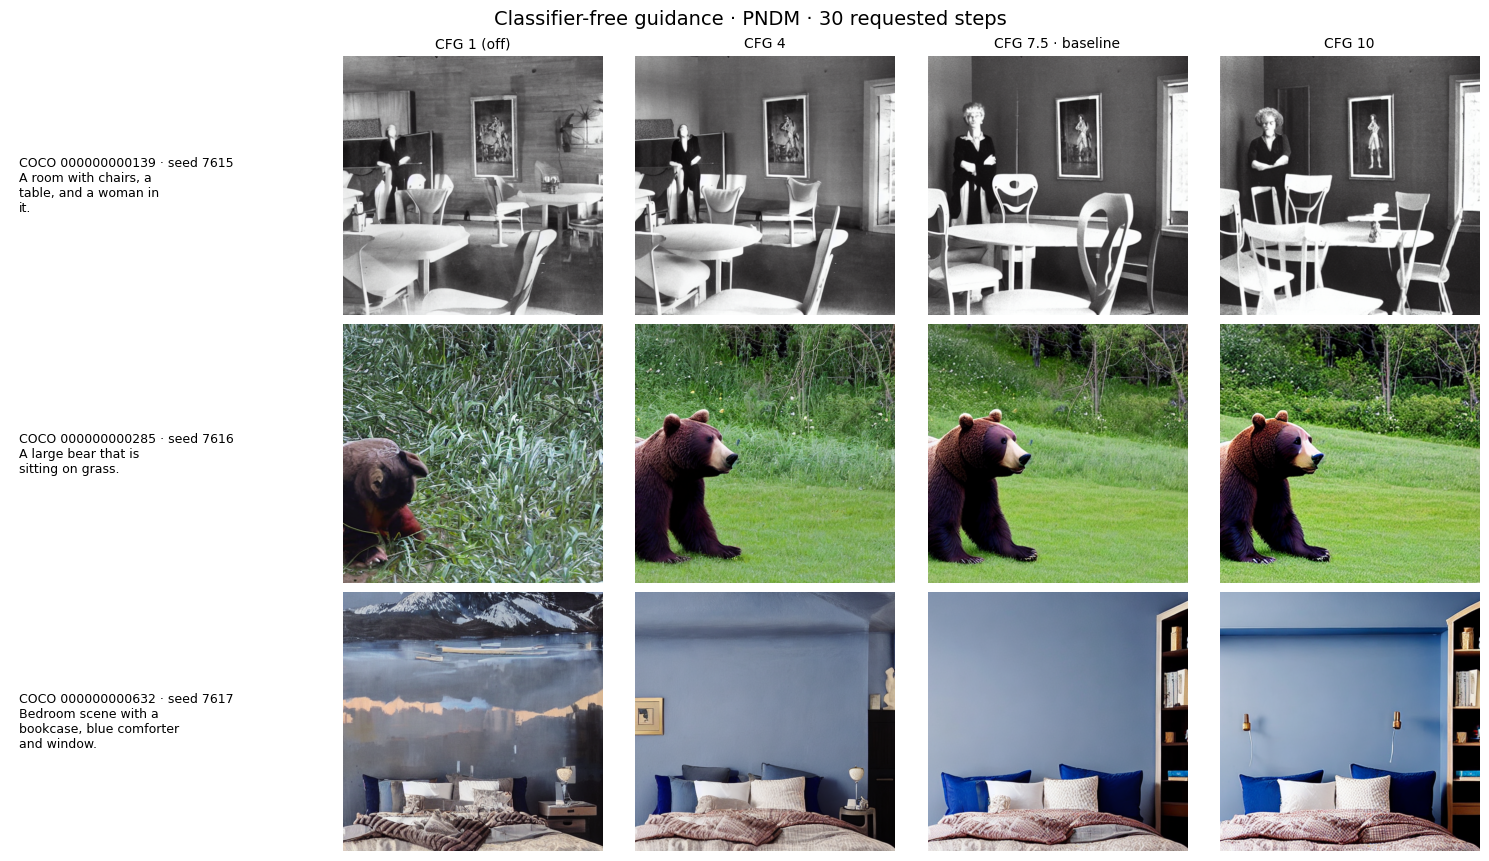

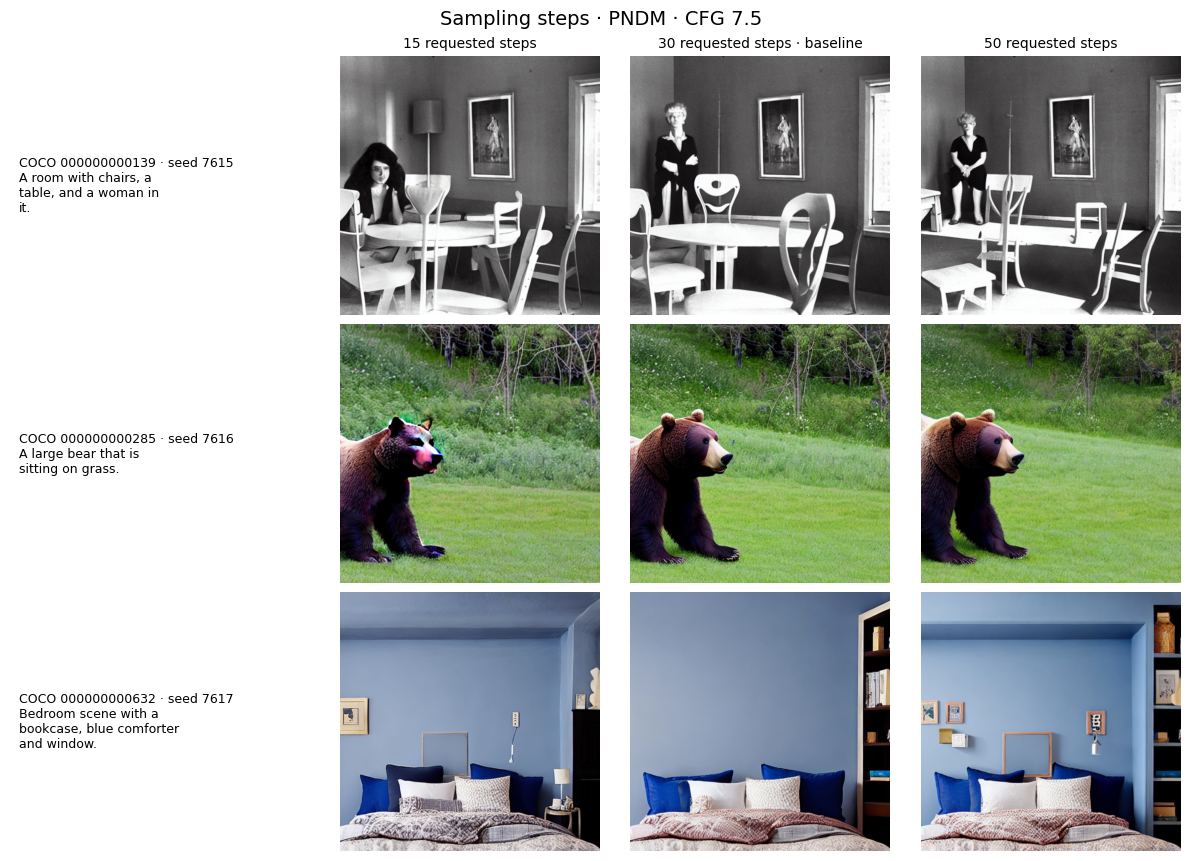

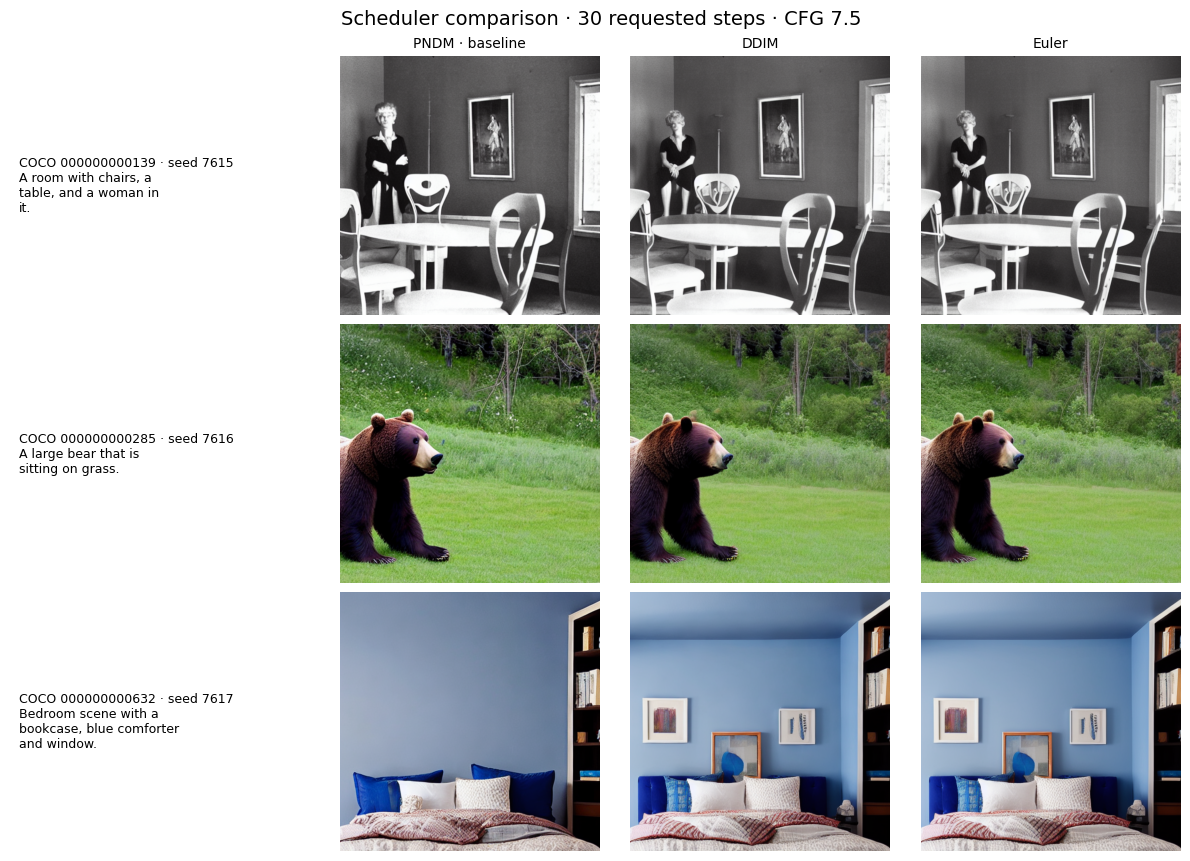

# Milestone 2 parameter experiment summary

Run `20261120T162837.037381Z` on Tesla T4 with FP16 Stable Diffusion 1.5.

Checkpoint `stable-diffusion-v1-5/stable-diffusion-v1-5` at revision `451f4fe16113bff5a5d2269ed5ad43b0592e9a14`.

Generated **26 unique experiment images** plus **one smoke image**. The five baseline images include the three references shared by every sweep.

[Five-image baseline gallery](grids/baseline_gallery.png) · [Per-image CSV](runs.csv) · [Full run metadata](run.json)

## Captions and baseline results

| COCO image ID | Seed | Caption | Coverage | Baseline seconds |
| --- | --- | --- | --- | --- |
| 139 | 7615 | A room with chairs, a table, and a woman in it. | Baseline and all sweeps | 4.74 |
| 285 | 7616 | A large bear that is sitting on grass. | Baseline and all sweeps | 4.81 |
| 632 | 7617 | Bedroom scene with a bookcase, blue comforter and window. | Baseline and all sweeps | 4.84 |
| 724 | 7618 | A stop sign is mounted upside-down on it's post. | Baseline | 4.87 |
| 776 | 7619 | Three stuffed bears hugging and sitting on a blue pillow | Baseline | 4.90 |

## Sweep results

Every setting below uses the same three captions and their fixed seeds. Mean pipeline time includes decoding and the safety checker. Times are descriptive single-run measurements from this session.

### Classifier-free guidance · PNDM · 30 requested steps

[Open comparison grid](grids/guidance_comparison.png)

| Scheduler | Requested steps | CFG | Images | Actual calls | Initial sigma | Mean pipeline seconds | Shared baseline |
| --- | --- | --- | --- | --- | --- | --- | --- |
| PNDM | 30 | 1 | 3 | 31 | 1 | 3.32 |  |
| PNDM | 30 | 4 | 3 | 31 | 1 | 5.41 |  |
| PNDM | 30 | 7.5 | 3 | 31 | 1 | 4.80 | Yes |
| PNDM | 30 | 10 | 3 | 31 | 1 | 5.46 |  |

### Sampling steps · PNDM · CFG 7.5

[Open comparison grid](grids/steps_comparison.png)

| Scheduler | Requested steps | CFG | Images | Actual calls | Initial sigma | Mean pipeline seconds | Shared baseline |
| --- | --- | --- | --- | --- | --- | --- | --- |
| PNDM | 15 | 7.5 | 3 | 16 | 1 | 2.94 |  |
| PNDM | 30 | 7.5 | 3 | 31 | 1 | 4.80 | Yes |
| PNDM | 50 | 7.5 | 3 | 51 | 1 | 8.88 |  |

### Scheduler comparison · 30 requested steps · CFG 7.5

[Open comparison grid](grids/scheduler_comparison.png)

| Scheduler | Requested steps | CFG | Images | Actual calls | Initial sigma | Mean pipeline seconds | Shared baseline |
| --- | --- | --- | --- | --- | --- | --- | --- |
| PNDM | 30 | 7.5 | 3 | 31 | 1 | 4.80 | Yes |
| DDIM | 30 | 7.5 | 3 | 30 | 1 | 5.35 |  |
| Euler | 30 | 7.5 | 3 | 30 | 11.5203 | 5.34 |  |

## Scope for observations

Describe prompt adherence, visible artifacts, and changes across each row after inspecting the grids. The schedule and initial noise sigma can differ across schedulers even when the raw draw is shared. At CFG 1, the negative condition is inactive. One seed per caption limits conclusions about variability.


Verified 27 generated PNGs, four grids, CSV, JSON, and report tables in /content/drive/MyDrive/IE7615/milestone2/parameter_experiments/20261120T162837.037381Z


In [7]:
import textwrap
from statistics import mean

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

grid_dir = run_dir / "grids"
grid_dir.mkdir(exist_ok=True)


def show_result(axis, row):
    with Image.open(run_dir / row["image_path"]) as source:
        axis.imshow(np.asarray(source))
    axis.set_xticks([])
    axis.set_yticks([])
    for spine in axis.spines.values():
        spine.set_visible(False)


def caption_label(image_id, width):
    sample = samples[image_id]
    return (f"COCO {image_id:012d} · seed {sample['seed']}\n"
            + textwrap.fill(sample["prompt"], width=width))


def column_label(group, setting):
    if group == "guidance":
        return f"CFG {setting.guidance:g}" + (" (off)" if setting.guidance == 1.0 else "")
    if group == "steps":
        return f"{setting.steps} requested steps"
    return setting.scheduler


figure_paths = {}
gallery, gallery_axes = plt.subplots(
    1, len(selected_ids), figsize=(16, 4.2), squeeze=False, layout="constrained"
)
gallery.suptitle("Stable Diffusion 1.5 baseline · PNDM · 30 requested steps · CFG 7.5", fontsize=14)
for axis, image_id in zip(gallery_axes[0], selected_ids):
    show_result(axis, completed[(image_id, baseline)])
    axis.set_title(caption_label(image_id, width=29), fontsize=9)
gallery_path = grid_dir / "baseline_gallery.png"
gallery.savefig(gallery_path, dpi=150, facecolor="white")
figure_paths["baseline_gallery"] = gallery_path.relative_to(run_dir).as_posix()
display(gallery)
plt.close(gallery)

comparison_titles = {
    "guidance": "Classifier-free guidance · PNDM · 30 requested steps",
    "steps": "Sampling steps · PNDM · CFG 7.5",
    "scheduler": "Scheduler comparison · 30 requested steps · CFG 7.5",
}
for group, settings in sweep_settings.items():
    fig, axes = plt.subplots(
        len(sweep_ids), len(settings) + 1, figsize=(3 * len(settings) + 2.9, 8.5),
        gridspec_kw={"width_ratios": [1.1] + [1] * len(settings)},
        squeeze=False, layout="constrained",
    )
    fig.suptitle(comparison_titles[group], fontsize=14)
    for row_index, image_id in enumerate(sweep_ids):
        label_axis = axes[row_index, 0]
        label_axis.axis("off")
        label_axis.text(0.03, 0.5, caption_label(image_id, width=24), va="center", fontsize=9)
        for column, setting in enumerate(settings, start=1):
            axis = axes[row_index, column]
            show_result(axis, completed[(image_id, setting)])
            if row_index == 0:
                suffix = " · baseline" if setting == baseline else ""
                axis.set_title(column_label(group, setting) + suffix, fontsize=10)
    path = grid_dir / f"{group}_comparison.png"
    fig.savefig(path, dpi=150, facecolor="white")
    figure_paths[group] = path.relative_to(run_dir).as_posix()
    display(fig)
    plt.close(fig)


def markdown_table(headers, rows):
    def line(values):
        return "| " + " | ".join(str(value).replace("|", "\\|").replace("\n", " ") for value in values) + " |"
    return "\n".join([line(headers), line(["---"] * len(headers)), *(line(row) for row in rows)])


caption_rows = [
    (image_id, sample["seed"], sample["prompt"],
     "Baseline and all sweeps" if image_id in sweep_ids else "Baseline",
     f"{completed[(image_id, baseline)]['pipeline_seconds']:.2f}")
    for image_id, sample in samples.items()
]
report = [
    "# Milestone 2 parameter experiment summary",
    f"Run `{run_id}` on {runtime_info['gpu']} with FP16 Stable Diffusion 1.5.",
    f"Checkpoint `{MODEL_ID}` at revision `{MODEL_REVISION}`.",
    f"Generated **{len(plan)} unique experiment images** plus **one smoke image**. "
    "The five baseline images include the three references shared by every sweep.",
    f"[Five-image baseline gallery]({figure_paths['baseline_gallery']}) · "
    "[Per-image CSV](runs.csv) · [Full run metadata](run.json)",
    "## Captions and baseline results",
    markdown_table(["COCO image ID", "Seed", "Caption", "Coverage", "Baseline seconds"], caption_rows),
    "## Sweep results",
    "Every setting below uses the same three captions and their fixed seeds. "
    "Mean pipeline time includes decoding and the safety checker. "
    "Times are descriptive single-run measurements from this session.",
]
summary_rows = {}
for group, settings in sweep_settings.items():
    rows = []
    for setting in settings:
        runs = [completed[(image_id, setting)] for image_id in sweep_ids]
        actual_steps = sorted({row["actual_steps"] for row in runs})
        sigma = sorted({row["initial_noise_sigma"] for row in runs})
        rows.append({
            "scheduler": setting.scheduler, "requested_steps": setting.steps,
            "cfg": setting.guidance, "is_baseline": setting == baseline, "images": len(runs),
            "actual_steps": actual_steps, "initial_noise_sigma": sigma,
            "mean_pipeline_seconds": mean(row["pipeline_seconds"] for row in runs),
        })
    summary_rows[group] = rows
    display_rows = [
        (row["scheduler"], row["requested_steps"], f"{row['cfg']:g}", row["images"],
         ", ".join(map(str, row["actual_steps"])),
         ", ".join(f"{sigma:.6g}" for sigma in row["initial_noise_sigma"]),
         f"{row['mean_pipeline_seconds']:.2f}", "Yes" if row["is_baseline"] else "")
        for row in rows
    ]
    report += [
        f"### {comparison_titles[group]}",
        f"[Open comparison grid]({figure_paths[group]})",
        markdown_table(
            ["Scheduler", "Requested steps", "CFG", "Images", "Actual calls", "Initial sigma",
             "Mean pipeline seconds", "Shared baseline"], display_rows,
        ),
    ]
report += [
    "## Scope for observations",
    "Describe prompt adherence, visible artifacts, and changes across each row after inspecting the grids. "
    "The schedule and initial noise sigma can differ across schedulers even when the raw draw is shared. "
    "At CFG 1, the negative condition is inactive. One seed per caption limits conclusions about variability.",
]
summary_markdown = "\n\n".join(report) + "\n"
(run_dir / "summary.md").write_text(summary_markdown, encoding="utf-8")

saved_images = {path.relative_to(run_dir).as_posix() for path in (run_dir / "images").glob("*.png")}
assert saved_images == {row["image_path"] for row in run_metadata["runs"]} and len(saved_images) == 27
assert len(figure_paths) == 4 and all((run_dir / path).is_file() for path in figure_paths.values())
with (run_dir / "runs.csv").open(encoding="utf-8", newline="") as handle:
    assert len(list(csv.DictReader(handle))) == 27
run_metadata.update(
    status="complete",
    finished_at_utc=datetime.now(timezone.utc).isoformat(),
    figures=figure_paths,
    summary_path="summary.md",
    sweep_summary=summary_rows,
)
write_metadata()
display(Markdown(summary_markdown))
print(f"Verified 27 generated PNGs, four grids, CSV, JSON, and report tables in {run_dir}")